# Hub-Lesion Degradation of Control Geometry and Target Energy

This notebook summarizes the targeted hub-removal analysis generated by `scripts/03_run_hub_lesion.py`.

- Hubs are the top degree-strength nodes for each subject and scale, with `h in {5, 10, 15}`.
- Driver rankings are computed on the intact network, but all removed hubs are ineligible for selection.
- The same eligible driver identities are evaluated on the intact and hub-deleted systems.
- Target vectors are masked to surviving nodes and renormalized in both systems, isolating degradation in the surviving control problem.

Positive degradation values indicate worse performance after hub deletion: higher log-energy or condition number, and lower effective rank or participation ratio. The key contrast is `Topology - Degree`; negative values indicate less degradation for topology-informed driver sets.

Set `HOC_RUN` (default `main`) to choose the run directory under `runs/`; `HOC_RUN=results` reads the legacy pre-cleanup tree.

In [8]:
from pathlib import Path
import os
import sys
os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from hoc.runs import resolve_run_dir, writable_root, figures_dir

RUN = os.environ.get('HOC_RUN', 'main')  # 'results' = legacy pre-cleanup tree
RESULTS = resolve_run_dir(RUN)
HUB_LESION_DIR = RESULTS / 'hub_lesion'
# derived tables written by this notebook (never into the legacy results/ tree)
HUB_LESION_OUT = writable_root(RESULTS) / 'hub_lesion'
HUB_LESION_OUT.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = figures_dir(RESULTS, 'section_hub_lesion')

methods = ['degree_strength', 'cycle_participation']
method_labels = {'degree_strength': 'Degree', 'cycle_participation': 'Topology'}
palette = {'degree_strength': '#cc7a29', 'cycle_participation': '#4c72b0'}
sns.set_theme(context='talk', style='whitegrid')


In [9]:
geometry = pd.read_csv(HUB_LESION_DIR / 'geometry_degradation.csv')
targets = pd.read_csv(HUB_LESION_DIR / 'target_energy_degradation.csv')
drivers = pd.read_csv(HUB_LESION_DIR / 'driver_sets.csv')

geometry = geometry[geometry['method'].isin(methods)].copy()
targets = targets[targets['method'].isin(methods)].copy()
geometry['method_label'] = geometry['method'].map(method_labels)
targets['method_label'] = targets['method'].map(method_labels)
display(drivers.head())
display(geometry.head())
display(targets.head())
display(targets.groupby(['target_name', 'hub_count'])['target_available'].mean().rename('proportion_available'))


,subject_id,scale,hub_count,k,method,selection_strategy,n_nodes_intact,n_nodes_lesioned,hub_node_indices,hub_region_labels,driver_node_indices_intact,driver_node_indices_lesioned,driver_region_labels
0,sub-000,68,5,1,degree_strength,intact_rank_nonhub_static,68,63,7;43;41;19;53,L_superiorfrontal;R_precentral;R_superiorfront...,8,7,L_caudalmiddlefrontal
1,sub-000,68,5,1,cycle_participation,intact_rank_nonhub_static,68,63,7;43;41;19;53,L_superiorfrontal;R_precentral;R_superiorfront...,48,44,R_isthmuscingulate
2,sub-000,68,5,2,degree_strength,intact_rank_nonhub_static,68,63,7;43;41;19;53,L_superiorfrontal;R_precentral;R_superiorfront...,8;9,7;8,L_caudalmiddlefrontal;L_precentral
3,sub-000,68,5,2,cycle_participation,intact_rank_nonhub_static,68,63,7;43;41;19;53,L_superiorfrontal;R_precentral;R_superiorfront...,48;44,44;40,R_isthmuscingulate;R_paracentral
4,sub-000,68,5,3,degree_strength,intact_rank_nonhub_static,68,63,7;43;41;19;53,L_superiorfrontal;R_precentral;R_superiorfront...,8;9;47,7;8;43,L_caudalmiddlefrontal;L_precentral;R_posterior...


,subject_id,scale,hub_count,k,method,selection_strategy,intact_log10_average_energy,lesioned_log10_average_energy,degradation_log10_average_energy,intact_effective_rank,...,degradation_effective_rank,intact_participation_ratio,lesioned_participation_ratio,degradation_participation_ratio,intact_condition_number,lesioned_condition_number,intact_log10_condition_number,lesioned_log10_condition_number,degradation_log10_condition_number,method_label
0,sub-000,68,5,1,degree_strength,intact_rank_nonhub_static,6.800413,6.760810,-0.039603,1.918624,...,0.430828,1.590258,1.255924,0.334334,39339.512530,69289.780769,4.594829,4.840669,0.245840,Degree
1,sub-000,68,5,1,cycle_participation,intact_rank_nonhub_static,6.801388,6.765451,-0.035937,1.819955,...,0.055011,1.512962,1.519043,-0.006081,32459.497893,45833.706270,4.511342,4.661185,0.149843,Topology
2,sub-000,68,5,2,degree_strength,intact_rank_nonhub_static,6.775656,6.733924,-0.041732,2.930264,...,0.536617,2.390886,1.957278,0.433607,63714.894996,86307.957117,4.804241,4.936051,0.131810,Degree
3,sub-000,68,5,2,cycle_participation,intact_rank_nonhub_static,6.777401,6.735792,-0.041610,3.071718,...,0.060346,2.711180,2.597267,0.113914,39151.054553,64289.604321,4.592743,4.808141,0.215397,Topology
4,sub-000,68,5,3,degree_strength,intact_rank_nonhub_static,6.752578,6.706034,-0.046544,3.988611,...,-0.011382,3.228325,3.350895,-0.122570,78307.765221,92679.041245,4.893805,4.966982,0.073177,Degree


,subject_id,scale,hub_count,k,method,selection_strategy,target_name,target_available,target_retained_norm,intact_target_energy,lesioned_target_energy,intact_log10_target_energy,lesioned_log10_target_energy,degradation_log10_target_energy,method_label
0,sub-000,68,5,1,degree_strength,intact_rank_nonhub_static,distributed_association,True,0.925820,69141.800891,43777.934856,4.839741,4.641255,-0.198485,Degree
1,sub-000,68,5,1,degree_strength,intact_rank_nonhub_static,occipital_module,True,0.894427,98041.097144,93295.115653,4.991408,4.969859,-0.021549,Degree
2,sub-000,68,5,1,degree_strength,intact_rank_nonhub_static,association_vs_occipital,True,0.970143,81257.488222,65466.231050,4.909863,4.816017,-0.093846,Degree
3,sub-000,68,5,1,degree_strength,intact_rank_nonhub_static,sparse_frontocingulate,True,0.912871,59994.143179,34926.742164,4.778109,4.543158,-0.234951,Degree
4,sub-000,68,5,1,degree_strength,intact_rank_nonhub_static,localized_association_peak,False,0.000000,NaN,NaN,NaN,NaN,NaN,Degree


target_name                 hub_count
association_vs_occipital    5            1.000000
                            10           1.000000
                            15           1.000000
bipolar_gradient            5            1.000000
                            10           1.000000
                            15           1.000000
distributed_association     5            1.000000
                            10           1.000000
                            15           1.000000
localized_association_peak  5            0.671429
                            10           0.628571
                            15           0.576190
localized_occipital_peak    5            0.952381
                            10           0.761905
                            15           0.609524
occipital_module            5            1.000000
                            10           1.000000
                            15           1.000000
principal_gradient          5            1.000000
            

## Geometry degradation

For effective rank and participation ratio, degradation is defined as intact minus lesioned so that positive values uniformly mean worsening.

In [10]:
metric_labels = {
    'degradation_effective_rank': 'Effective rank loss',
    'degradation_participation_ratio': 'Participation ratio loss',
    'degradation_log10_condition_number': 'Condition number increase (log10)',
    'degradation_log10_average_energy': 'Average energy increase (log10)',
}
geometry_long = geometry.melt(
    id_vars=['subject_id', 'scale', 'hub_count', 'k', 'method', 'method_label'],
    value_vars=list(metric_labels),
    var_name='metric',
    value_name='degradation',
)
geometry_long['metric_label'] = geometry_long['metric'].map(metric_labels)
geometry_summary = (
    geometry_long.groupby(['scale', 'hub_count', 'k', 'method', 'method_label', 'metric_label'], as_index=False)
    .agg(mean_degradation=('degradation', 'mean'), sem_degradation=('degradation', 'sem'))
)
display(geometry_summary.head(12))


,scale,hub_count,k,method,method_label,metric_label,mean_degradation,sem_degradation
0,68,5,1,cycle_participation,Topology,Average energy increase (log10),-0.039264,0.000374
1,68,5,1,cycle_participation,Topology,Condition number increase (log10),0.312202,0.016443
2,68,5,1,cycle_participation,Topology,Effective rank loss,-0.009760,0.028885
3,68,5,1,cycle_participation,Topology,Participation ratio loss,-0.007939,0.020466
4,68,5,1,degree_strength,Degree,Average energy increase (log10),-0.038056,0.000445
5,68,5,1,degree_strength,Degree,Condition number increase (log10),0.310570,0.027224
6,68,5,1,degree_strength,Degree,Effective rank loss,0.166533,0.037748
7,68,5,1,degree_strength,Degree,Participation ratio loss,0.123347,0.027259
8,68,5,2,cycle_participation,Topology,Average energy increase (log10),-0.045746,0.000638
9,68,5,2,cycle_participation,Topology,Condition number increase (log10),0.340375,0.020462


In [11]:
comparison_rows = []
for (scale, hub_count, k, metric), subset in geometry_long.groupby(['scale', 'hub_count', 'k', 'metric']):
    paired = subset.pivot(index='subject_id', columns='method', values='degradation').dropna()
    difference = paired['cycle_participation'] - paired['degree_strength']
    try:
        statistic, p_value = wilcoxon(difference)
    except ValueError:
        statistic, p_value = np.nan, 1.0
    comparison_rows.append({
        'scale': scale, 'hub_count': hub_count, 'k': k, 'metric': metric,
        'metric_label': metric_labels[metric], 'n_subjects': len(difference),
        'topology_minus_degree_mean_degradation': difference.mean(),
        'topology_minus_degree_median_degradation': difference.median(),
        'wilcoxon_statistic': statistic, 'p_value': p_value,
    })
geometry_comparison = pd.DataFrame(comparison_rows)
geometry_comparison['p_holm'] = multipletests(geometry_comparison['p_value'], method='holm')[1]
geometry_comparison.to_csv(HUB_LESION_OUT / 'geometry_strategy_comparison.csv', index=False)
display(geometry_comparison.sort_values('p_holm').head(20))


,scale,hub_count,k,metric,metric_label,n_subjects,topology_minus_degree_mean_degradation,topology_minus_degree_median_degradation,wilcoxon_statistic,p_value,p_holm
109,219,5,5,degradation_log10_average_energy,Average energy increase (log10),70,-0.001357,-0.001332,96.0,1.952558e-11,2.811683e-09
72,114,10,3,degradation_effective_rank,Effective rank loss,70,-0.560439,-0.634810,164.0,2.762028e-10,3.949700e-08
71,114,10,2,degradation_participation_ratio,Participation ratio loss,70,-0.355336,-0.339571,171.0,3.596279e-10,5.106716e-08
77,114,10,5,degradation_log10_average_energy,Average energy increase (log10),70,-0.003962,-0.003561,189.0,7.036102e-10,9.920904e-08
75,114,10,3,degradation_participation_ratio,Participation ratio loss,70,-0.519697,-0.505406,210.0,1.518586e-09,2.126021e-07
61,114,5,5,degradation_log10_average_energy,Average energy increase (log10),70,-0.002883,-0.003023,215.0,1.819889e-09,2.529645e-07
92,114,15,5,degradation_effective_rank,Effective rank loss,70,-0.635937,-0.639934,241.0,4.601963e-09,6.350710e-07
91,114,15,3,degradation_participation_ratio,Participation ratio loss,70,-0.431324,-0.413269,241.0,4.601963e-09,6.350710e-07
68,114,10,2,degradation_effective_rank,Effective rank loss,70,-0.412796,-0.342430,254.0,7.256302e-09,9.868571e-07
76,114,10,5,degradation_effective_rank,Effective rank loss,70,-0.727520,-0.770852,256.0,7.779012e-09,1.050167e-06


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_hub_lesion/hub_lesion_geometry_degradation.svg')

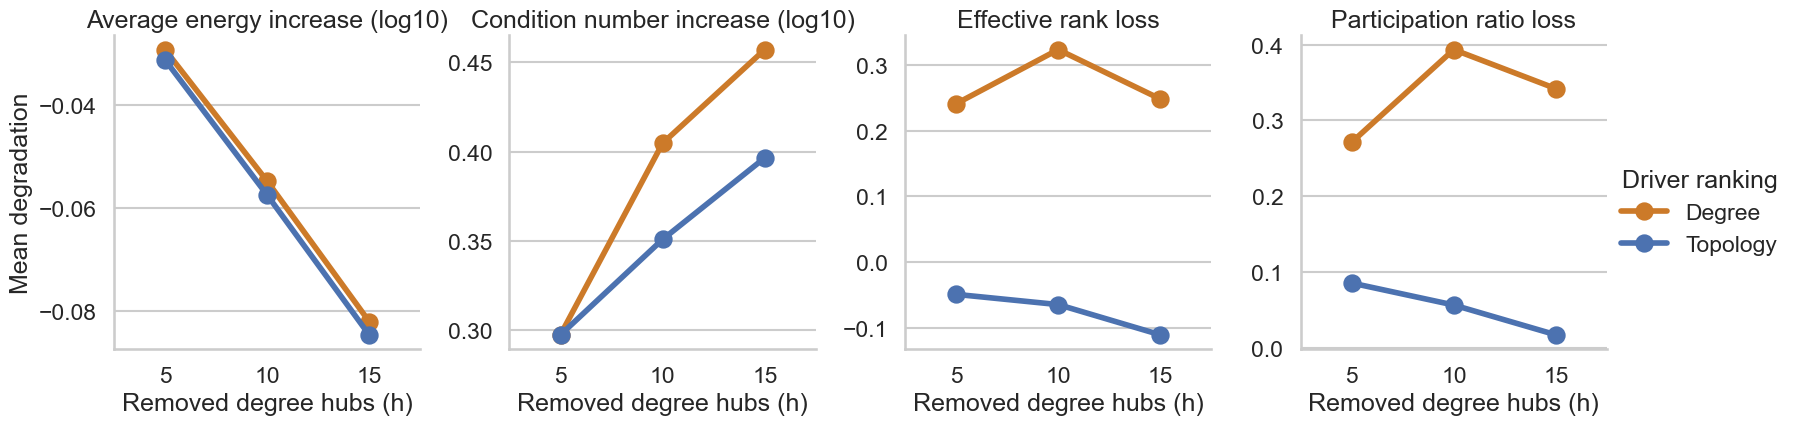

In [12]:
plot_data = geometry_long.groupby(['hub_count', 'method_label', 'metric_label'], as_index=False)['degradation'].mean()
g = sns.catplot(
    data=plot_data, x='hub_count', y='degradation', hue='method_label',
    col='metric_label', kind='point', palette={method_labels[k]: v for k, v in palette.items()},
    sharey=False, height=4.6, aspect=0.9,
)
g.set_axis_labels('Removed degree hubs (h)', 'Mean degradation')
g.set_titles('{col_name}')
g.legend.set_title('Driver ranking')
out = FIGURES_DIR / 'hub_lesion_geometry_degradation.svg'
g.figure.savefig(out, bbox_inches='tight')
display(out)
plt.show()


## Target-state energy degradation

Each target-energy change is represented as `log10(lesioned / intact)` on the matched surviving target. When deleting hubs removes all support for a localized target, that condition is recorded as unavailable and omitted from paired energy tests.

In [13]:
target_paired = targets.pivot_table(
    index=['subject_id', 'scale', 'hub_count', 'k', 'target_name'],
    columns='method', values='degradation_log10_target_energy',
).dropna().reset_index()
target_paired['topology_minus_degree'] = (
    target_paired['cycle_participation'] - target_paired['degree_strength']
)
target_summary = (
    target_paired.groupby(['target_name', 'hub_count'], as_index=False)
    .agg(mean_topology_minus_degree=('topology_minus_degree', 'mean'),
         median_topology_minus_degree=('topology_minus_degree', 'median'))
)
target_rows = []
for (target_name, hub_count), subset in target_paired.groupby(['target_name', 'hub_count']):
    try:
        statistic, p_value = wilcoxon(subset['topology_minus_degree'])
    except ValueError:
        statistic, p_value = np.nan, 1.0
    target_rows.append({'target_name': target_name, 'hub_count': hub_count,
                        'n_conditions': len(subset), 'wilcoxon_statistic': statistic, 'p_value': p_value})
target_tests = pd.DataFrame(target_rows)
target_tests['p_holm'] = multipletests(target_tests['p_value'], method='holm')[1]
target_summary = target_summary.merge(target_tests, on=['target_name', 'hub_count'])
target_summary.to_csv(HUB_LESION_OUT / 'target_strategy_comparison.csv', index=False)
display(target_summary.sort_values('p_holm'))


,target_name,hub_count,mean_topology_minus_degree,median_topology_minus_degree,n_conditions,wilcoxon_statistic,p_value,p_holm
11,localized_association_peak,15,-0.031370,-0.004377,484,37154.0,2.001097e-11,4.802633e-10
10,localized_association_peak,10,-0.019715,-0.002828,528,49500.0,1.049278e-07,2.413339e-06
9,localized_association_peak,5,-0.012918,-0.001373,564,60058.0,1.894004e-06,4.166809e-05
8,distributed_association,15,0.013976,0.004868,840,137900.0,4.523647e-06,9.499659e-05
6,distributed_association,5,0.011529,0.012334,840,141963.0,8.113843e-06,1.622769e-04
7,distributed_association,10,0.012524,0.008406,840,141051.0,4.699845e-05,8.929705e-04
23,sparse_frontocingulate,15,0.042687,0.002135,836,143032.0,2.975086e-04,5.355155e-03
15,occipital_module,5,0.008522,0.001286,840,153593.0,5.404240e-03,9.187209e-02
19,principal_gradient,10,-0.010790,-0.005701,840,150060.0,6.057631e-03,9.692210e-02
17,occipital_module,15,-0.011033,-0.002255,840,151795.0,1.092132e-02,1.638198e-01


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_hub_lesion/hub_lesion_target_energy_contrast.svg')

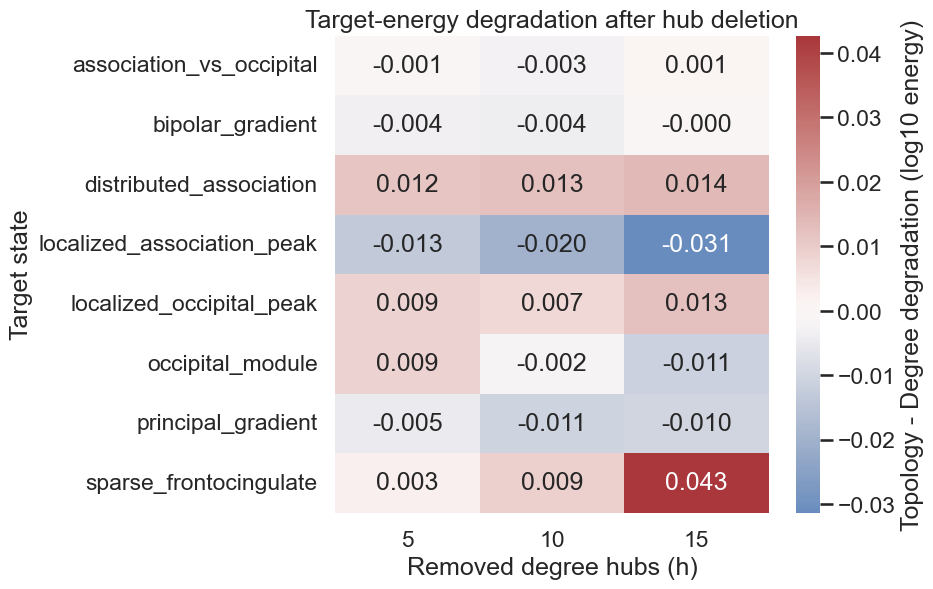

In [14]:
heatmap = target_summary.pivot(index='target_name', columns='hub_count', values='mean_topology_minus_degree')
fig, ax = plt.subplots(figsize=(7.0, 6.2))
sns.heatmap(heatmap, cmap='vlag', center=0.0, annot=True, fmt='.3f', ax=ax,
            cbar_kws={'label': 'Topology - Degree degradation (log10 energy)'})
ax.set_xlabel('Removed degree hubs (h)')
ax.set_ylabel('Target state')
ax.set_title('Target-energy degradation after hub deletion')
out = FIGURES_DIR / 'hub_lesion_target_energy_contrast.svg'
fig.savefig(out, bbox_inches='tight')
display(out)
plt.show()
